# AUT-2802 Machine Vision | Recognising pet breeds

How much does ImageNet pretraining help a classifier distinguish the 37 breeds in the Oxford-IIIT Pet dataset? We compare initialisation, training conditions and hyperparameters while keeping the training and validation images fixed. The final comparison measures how well each selected checkpoint generalises to the official test set.

| Part | Question | Evidence produced |
|---|---|---|
| A | How do the classifiers differ? | Architecture descriptions and parameter counts after replacing the classification head |
| B | How does pretraining affect learning under a fixed epoch budget? | Validation curves and final-epoch scores for each initialisation |
| C | How does the combined regularisation strategy affect validation performance? | Clean validation scores and accuracy across three augmented passes |
| D | Which sampled settings reach the lowest validation loss? | Trial settings and metrics at each trial's best epoch |
| E | Which breeds are difficult to distinguish on unseen images? | Held-out scores, per-breed reports and confusion matrices |

The supplied configuration includes ResNet18 and AlexNet. EfficientNet-B0 is implemented as an optional third architecture. The list printed in setup identifies the models included in a run.

## Setup and execution

Run the cells in order from a fresh Jupyter kernel. The first run needs access to the Oxford-IIIT Pet dataset and the pretrained TorchVision weights, either through their local caches or a download. Part D uses Ray Tune for trial configuration and per-epoch reporting. The optional installation cell specifies Ray 2.60.0 for a fresh environment.

Choose the architectures in `MODEL_NAMES` using the configuration below. To collect report results, set `QUICK_RUN = False` and enable B, C and D. Enable `RUN_FINAL_TEST` after fixing the candidate architectures and training settings. Quick and full runs write to separate directories. Repeating a run with the same settings can replace its result files.

In [9]:
# Execute only if the dependencies are not already installed.
# %pip install torch torchvision scikit-learn pandas matplotlib "ray[tune]==2.60.0"

In [10]:
from pathlib import Path
import json
import os
import platform
import random
import time

# Set before the first Ray import. If Ray was already imported, restart the kernel.
os.environ["RAY_AIR_NEW_OUTPUT"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

# Shared settings: all three architectures must use identical data partitions.
SEED = 42
NUM_CLASSES = 37
IMAGE_SIZE = 224
DATA_DIR = Path("data").resolve()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0  # Suitable for Jupyter on Windows; increase on other systems if desired.
BATCH_SIZE = 32 if DEVICE.type == "cuda" else 16

# QUICK_RUN verifies that the pipeline executes; it is NOT a report-quality experiment.
QUICK_RUN = False
OUTPUT_DIR = Path("exam_results", "quick" if QUICK_RUN else "full").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EPOCHS_B = 2 if QUICK_RUN else 10
EPOCHS_C = 2 if QUICK_RUN else 10
EPOCHS_D = 2 if QUICK_RUN else 10
PATIENCE = 3

# Enable the optional branch only if EfficientNet-B0 is the chosen third model.
THIRD_MODEL = None  # Set to 'efficientnet_b0' or register another architecture below.
MODEL_NAMES = ["resnet18", "alexnet"] + ([THIRD_MODEL] if THIRD_MODEL else [])

RUN_B = True
RUN_C = True
RUN_D = True
RUN_FINAL_TEST = True


def set_seed(seed=SEED):
    """Initialize common random generators for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
print(f"Python {platform.python_version()} | PyTorch {torch.__version__}")
print(f"TorchVision {__import__('torchvision').__version__} | Device: {DEVICE}")
print(f"Models: {MODEL_NAMES} | QUICK_RUN: {QUICK_RUN}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Result files:", OUTPUT_DIR)

Python 3.13.18 | PyTorch 2.14.1+cu132
TorchVision 0.29.1+cu132 | Device: cuda
Models: ['resnet18', 'alexnet'] | QUICK_RUN: False
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
Result files: C:\Users\Robin\Downloads\exam_results\full


## Data and preprocessing

A stratified split assigns 80% of the official training partition to training and 20% to validation. Stratification keeps the breed proportions similar. Both validation loaders use the same image indices, so the difference between their scores reflects a change in image processing.

All inputs are resized to 224 × 224 and normalised channel by channel using ImageNet statistics. Part B uses these deterministic transforms. Parts C–E also flip, rotate and occasionally mask a square of the training image (Cutout). Clean validation loss determines the selected checkpoint. The augmented validation loader measures sensitivity to these transformations. The official test images receive only deterministic preprocessing.

In [11]:
# ImageNet normalization constants used for every architecture.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


class Cutout:
    """Randomly mask one square patch in a CHW float tensor before normalization."""

    def __init__(self, size=32, p=0.5, fill=0.0):
        self.size = int(size)
        self.p = float(p)
        self.fill = float(fill)
        if self.size < 1 or not (0.0 <= self.p <= 1.0):
            raise ValueError("Cutout requires size >= 1 and probability in [0, 1].")

    def __call__(self, image):
        if torch.rand(()).item() >= self.p:
            return image
        _, height, width = image.shape
        # Sample a valid corner so the whole square fits, including at image edges.
        side = min(self.size, height, width)
        top = int(torch.randint(height - side + 1, (1,)).item())
        left = int(torch.randint(width - side + 1, (1,)).item())
        bottom, right = top + side, left + side
        # Work on a copy so the unmasked input remains available.
        image = image.clone()
        image[:, top:bottom, left:right] = self.fill
        return image


clean_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


def make_aug_transform(cutout_p=0.5, cutout_size=32):
    """Training/augmented-validation transform shared across all architectures."""
    return transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ToTensor(),
        Cutout(size=cutout_size, p=cutout_p),
        transforms.Normalize(MEAN, STD),
    ])


# The official trainval set is split once, with preserved class proportions.
base_trainval = datasets.OxfordIIITPet(
    root=str(DATA_DIR), split="trainval", target_types="category", download=True
)
base_test = datasets.OxfordIIITPet(
    root=str(DATA_DIR), split="test", target_types="category", download=True
)
labels = np.array([base_trainval[i][1] for i in range(len(base_trainval))])
train_indices, val_indices = train_test_split(
    np.arange(len(base_trainval)),
    test_size=0.20,
    random_state=SEED,
    stratify=labels,
)
assert set(train_indices).isdisjoint(set(val_indices))


def make_loaders(batch_size=BATCH_SIZE, augment=False, cutout_p=0.5, cutout_size=32):
    """Return (train, clean validation, augmented validation, untouched test)."""
    train_transform = (
        make_aug_transform(cutout_p, cutout_size) if augment else clean_transform
    )
    train_dataset = datasets.OxfordIIITPet(
        root=str(DATA_DIR), split="trainval", target_types="category",
        transform=train_transform, download=False
    )
    val_dataset = datasets.OxfordIIITPet(
        root=str(DATA_DIR), split="trainval", target_types="category",
        transform=clean_transform, download=False
    )
    val_aug_dataset = datasets.OxfordIIITPet(
        root=str(DATA_DIR), split="trainval", target_types="category",
        transform=make_aug_transform(cutout_p, cutout_size), download=False
    )
    test_dataset = datasets.OxfordIIITPet(
        root=str(DATA_DIR), split="test", target_types="category",
        transform=clean_transform, download=False
    )
    settings = dict(
        batch_size=batch_size,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )
    # An independent generator keeps image order separate from model initialisation.
    generator = torch.Generator().manual_seed(SEED)
    return (
        DataLoader(Subset(train_dataset, train_indices), shuffle=True, generator=generator, **settings),
        DataLoader(Subset(val_dataset, val_indices), shuffle=False, **settings),
        DataLoader(Subset(val_aug_dataset, val_indices), shuffle=False, **settings),
        DataLoader(test_dataset, shuffle=False, **settings),
    )


train_clean, val_clean, val_aug, test_loader = make_loaders(augment=False)
print(f"Training: {len(train_indices)} | Validation: {len(val_indices)} | Test: {len(base_test)}")

Training: 2944 | Validation: 736 | Test: 3669


### 1.1 Visual verification of data augmentation

The plot shows one original image alongside independently transformed examples. For illustration only, Cutout is forced on (`p=1`) to make the masked region visible; the actual training probability is `p=0.5`. The figure is saved to the results directory for possible inclusion in the report.

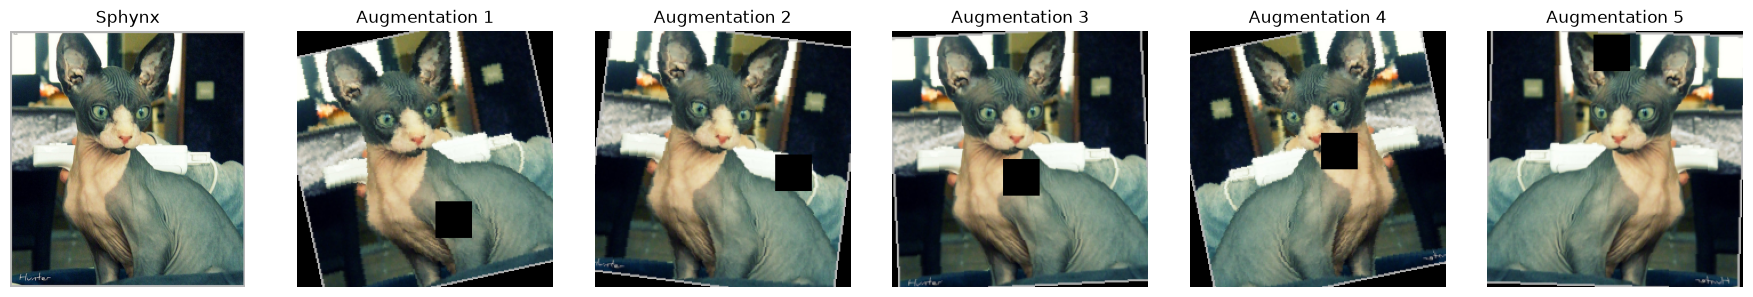

In [12]:
def show_augmentations(index=None, n_examples=5):
    """Display independently augmented versions of a single training image."""
    index = int(train_indices[0]) if index is None else int(index)
    original, class_id = base_trainval[index]
    transform = make_aug_transform(cutout_p=1.0, cutout_size=32)
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)

    fig, axes = plt.subplots(1, n_examples + 1, figsize=(3 * (n_examples + 1), 3))
    axes[0].imshow(original)
    axes[0].set_title(f"{base_trainval.classes[class_id]}")
    axes[0].axis("off")
    for index_plot in range(n_examples):
        # Undo normalisation and move the colour dimension last for Matplotlib.
        augmented = (transform(original) * std + mean).clamp(0, 1)
        axes[index_plot + 1].imshow(augmented.permute(1, 2, 0))
        axes[index_plot + 1].set_title(f"Augmentation {index_plot + 1}")
        axes[index_plot + 1].axis("off")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "augmentation_examples.png", dpi=180, bbox_inches="tight")
    plt.show()


show_augmentations()

## A. Classifier architectures

| Architecture | Feature extraction | Adaptation for breed classification |
|---|---|---|
| ResNet18 | Residual blocks add a shortcut to a sequence of convolutions, allowing gradients to flow through the shortcut. | Replace the final fully connected layer. |
| AlexNet | Stacked convolution and pooling layers feed a fully connected classifier with dropout. | Replace the last linear layer in the classifier. |
| EfficientNet-B0 (optional) | Inverted residual blocks use depthwise convolutions and channel weighting. | Replace the linear layer following dropout. |

Each new output layer produces one raw score (logit) per breed. All layers can update during training, including the pretrained feature extractor. Parameter counts below refer to the adapted networks.

In [13]:
def make_model(name, pretrained=True):
    """Construct a classification network with exactly 37 output logits."""
    # Keep the feature extractor and match the output width to the breed labels.
    if name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    elif name == "alexnet":
        weights = models.AlexNet_Weights.DEFAULT if pretrained else None
        model = models.alexnet(weights=weights)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, NUM_CLASSES)
    elif name == "efficientnet_b0":
        # Optional third architecture: replace with the selected model as needed.
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)
    else:
        raise ValueError(f"Model {name!r} is not registered in make_model().")
    return model


architecture_table = pd.DataFrame([
    {
        "architecture": name,
        "parameters_million": sum(
            parameter.numel() for parameter in make_model(name, pretrained=False).parameters()
        ) / 1e6,
    }
    for name in MODEL_NAMES
])
display(architecture_table)
architecture_table.to_csv(OUTPUT_DIR / "A_architecture_parameters.csv", index=False)

,architecture,parameters_million
0,resnet18,11.195493
1,alexnet,57.155429


## 3. Shared optimization and evaluation functions

A common loop is required to compare architectures without introducing procedural differences. Training uses cross-entropy loss and the Adam optimizer, matching the original group scripts. For each epoch, the notebook records loss, accuracy, macro-F1 and elapsed time. Evaluation disables gradients and never updates model weights.

For experiments with early stopping, the best weights are retained according to **clean validation loss**. Macro-F1 is a complementary metric that gives each breed equal weight and is useful for assessing class-level consistency. The training history and plots are exported for reproducibility.

In [14]:
def run_epoch(model, loader, optimizer=None, device=DEVICE, collect_predictions=False):
    """Execute one training or inference epoch and return aggregate metrics."""
    training = optimizer is not None
    # Evaluation mode fixes dropout and batch-normalisation behaviour.
    model.train(training)
    criterion = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    true_labels, predicted_labels = [], []

    with torch.enable_grad() if training else torch.no_grad():
        for images, targets in loader:
            images = images.to(device)
            targets = targets.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()

            predictions = logits.argmax(dim=1)
            batch_size = targets.size(0)
            # Weight by image count so a shorter final batch contributes fairly.
            loss_sum += loss.item() * batch_size
            correct += (predictions == targets).sum().item()
            total += batch_size
            true_labels.extend(targets.cpu().tolist())
            predicted_labels.extend(predictions.cpu().tolist())

    metrics = {
        "loss": loss_sum / total,
        "acc": correct / total,
        "macro_f1": f1_score(true_labels, predicted_labels, average="macro", zero_division=0),
    }
    if collect_predictions:
        metrics.update(targets=true_labels, predictions=predicted_labels)
    return metrics


def fit_model(name, pretrained, train_loader, val_loader, *, epochs,
              lr=0.001, weight_decay=0.0, early_stopping=False,
              patience=PATIENCE, report_fn=None, device=DEVICE):
    """Fit one model and restore the best validation-loss checkpoint when requested."""
    set_seed()
    model = make_model(name, pretrained=pretrained).to(device)
    # Reset the sampler even when several fits share a loader (parts B and C).
    train_loader.generator.manual_seed(SEED)
    # Weight decay penalises large weights. A value of zero disables it in part B.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = []
    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        train_metrics = run_epoch(model, train_loader, optimizer=optimizer, device=device)
        val_metrics = run_epoch(model, val_loader, device=device)
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_acc": train_metrics["acc"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_acc": val_metrics["acc"],
            "val_macro_f1": val_metrics["macro_f1"],
            "epoch_seconds": time.perf_counter() - start,
        })
        print(
            f"{name} | epoch {epoch:02d}/{epochs:02d} | "
            f"training accuracy={train_metrics['acc']:.3f} | "
            f"validation accuracy={val_metrics['acc']:.3f} | "
            f"validation loss={val_metrics['loss']:.3f}"
        )

        if val_metrics["loss"] < best_loss:
            best_loss = val_metrics["loss"]
            best_epoch = epoch
            # Keep an independent CPU snapshot before another epoch changes the weights.
            if early_stopping:
                best_state = {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if report_fn is not None:
            report_fn({
                "loss": val_metrics["loss"],
                "accuracy": val_metrics["acc"],
                "val_macro_f1": val_metrics["macro_f1"],
                "epoch": epoch,
            })
        if early_stopping and epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}; best epoch: {best_epoch}.")
            break

    if early_stopping and best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


def plot_history(history, title, filename=None):
    """Plot recorded accuracy and loss curves and optionally save the figure."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["epoch"], history["train_acc"], label="Training")
    axes[0].plot(history["epoch"], history["val_acc"], label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy", title="Classification accuracy")
    axes[1].plot(history["epoch"], history["train_loss"], label="Training")
    axes[1].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    for axis in axes:
        axis.legend()
        axis.grid(alpha=0.2)
    fig.suptitle(title)
    fig.tight_layout()
    if filename:
        fig.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

## B. Effect of ImageNet initialisation

For each architecture, the two runs use the same images, batch order, Adam learning rate (0.001) and epoch budget. Both runs use clean images and zero weight decay. The comparison uses the final epoch in each run. The curves show whether an early advantage persists through the end of training.

resnet18 | epoch 01/10 | training accuracy=0.061 | validation accuracy=0.043 | validation loss=4.406
resnet18 | epoch 02/10 | training accuracy=0.111 | validation accuracy=0.103 | validation loss=3.377
resnet18 | epoch 03/10 | training accuracy=0.153 | validation accuracy=0.121 | validation loss=3.349
resnet18 | epoch 04/10 | training accuracy=0.186 | validation accuracy=0.137 | validation loss=3.134
resnet18 | epoch 05/10 | training accuracy=0.202 | validation accuracy=0.098 | validation loss=3.996
resnet18 | epoch 06/10 | training accuracy=0.242 | validation accuracy=0.151 | validation loss=3.474
resnet18 | epoch 07/10 | training accuracy=0.272 | validation accuracy=0.186 | validation loss=2.894
resnet18 | epoch 08/10 | training accuracy=0.338 | validation accuracy=0.141 | validation loss=4.119
resnet18 | epoch 09/10 | training accuracy=0.390 | validation accuracy=0.232 | validation loss=2.813
resnet18 | epoch 10/10 | training accuracy=0.437 | validation accuracy=0.173 | validation l

,model,initialization,val_loss,val_acc,val_macro_f1,train_seconds
0,resnet18,random,3.838422,0.172554,0.143135,379.685825
1,resnet18,pretrained,1.285828,0.682065,0.681171,281.625403
2,alexnet,random,3.610829,0.027174,0.001430,212.460832
3,alexnet,pretrained,3.610904,0.027174,0.001430,190.330927


,Pretraining gain (percentage points)
model,
alexnet,0.00
resnet18,50.95


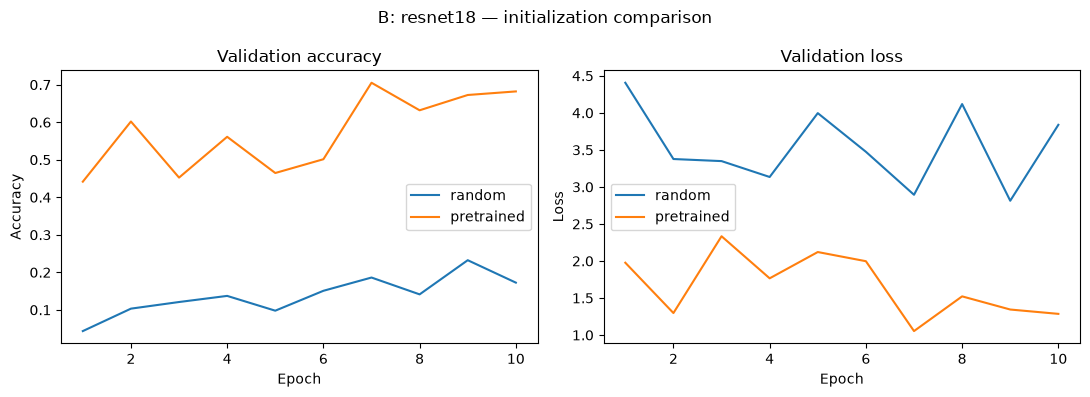

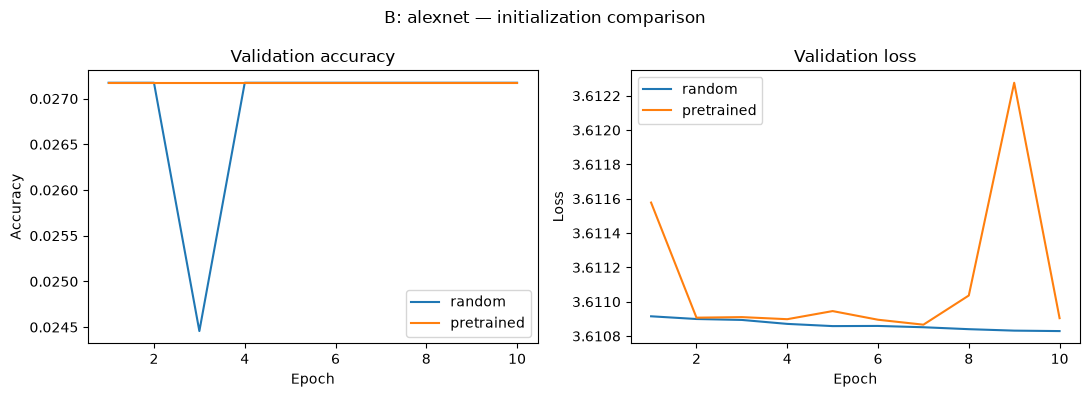

In [15]:
b_rows = []
b_histories = {}
if RUN_B:
    train_b, val_b, _, _ = make_loaders(augment=False)
    for name in MODEL_NAMES:
        for pretrained in [False, True]:
            label = 'pretrained' if pretrained else 'random'
            # A fixed budget makes the final epochs directly comparable.
            model, history, _ = fit_model(
                name, pretrained, train_b, val_b, epochs=EPOCHS_B,
                lr=0.001, weight_decay=0, early_stopping=False,
            )
            last = history.iloc[-1]
            b_rows.append({
                "model": name,
                "initialization": label,
                "val_loss": last["val_loss"],
                "val_acc": last["val_acc"],
                "val_macro_f1": last["val_macro_f1"],
                "train_seconds": history["epoch_seconds"].sum(),
            })
            b_histories[(name, label)] = history
            history.to_csv(OUTPUT_DIR / f'B_{name}_{label}_history.csv', index=False)
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    b_results = pd.DataFrame(b_rows)
    b_results.to_csv(OUTPUT_DIR / 'B_initialization_results.csv', index=False)
    display(b_results)
    # Percentage points express the absolute accuracy difference on a 0–100 scale.
    paired = b_results.pivot(index="model", columns="initialization", values="val_acc")
    gain = 100 * (paired["pretrained"] - paired["random"])
    display(gain.round(2).to_frame("Pretraining gain (percentage points)"))
    for name in MODEL_NAMES:
        fig, ax = plt.subplots(1, 2, figsize=(11,4))
        for label in ('random','pretrained'):
            h = b_histories[(name,label)]
            ax[0].plot(h.epoch, h.val_acc, label=label)
            ax[1].plot(h.epoch, h.val_loss, label=label)
        ax[0].set(xlabel='Epoch', ylabel='Accuracy', title='Validation accuracy')
        ax[1].set(xlabel='Epoch', ylabel='Loss', title='Validation loss')
        for axis in ax:
            axis.legend()
        fig.suptitle(f'B: {name} — initialization comparison')
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f'B_{name}_comparison.png', dpi=160)
        plt.show()
else:
    print('B not run. Set RUN_B=True in setup, then rerun this cell.')

## C. Augmentation, weight decay and early stopping

Starting from ImageNet weights, each model trains with horizontal flipping (probability 0.5), rotation (up to 15° in either direction) and a 32 × 32 Cutout mask (probability 0.5). Adam uses a learning rate of 0.001 and weight decay of 0.0001. Training stops after three consecutive epochs without a lower clean validation loss, or when the epoch budget is exhausted. Evaluation uses the weights from the lowest-loss epoch.

Compare the clean scores with the pretrained run in part B. Several training choices change together, so that comparison estimates their combined effect. The augmented validation mean and standard deviation describe variation across three transformations of the same validation set. They do not measure uncertainty across independent training runs.

resnet18 | epoch 01/10 | training accuracy=0.497 | validation accuracy=0.501 | validation loss=1.688
resnet18 | epoch 02/10 | training accuracy=0.660 | validation accuracy=0.469 | validation loss=1.821
resnet18 | epoch 03/10 | training accuracy=0.727 | validation accuracy=0.511 | validation loss=1.968
resnet18 | epoch 04/10 | training accuracy=0.779 | validation accuracy=0.701 | validation loss=1.079
resnet18 | epoch 05/10 | training accuracy=0.810 | validation accuracy=0.707 | validation loss=1.069
resnet18 | epoch 06/10 | training accuracy=0.838 | validation accuracy=0.618 | validation loss=1.470
resnet18 | epoch 07/10 | training accuracy=0.842 | validation accuracy=0.688 | validation loss=1.086
resnet18 | epoch 08/10 | training accuracy=0.861 | validation accuracy=0.717 | validation loss=0.958
resnet18 | epoch 09/10 | training accuracy=0.890 | validation accuracy=0.727 | validation loss=0.956
resnet18 | epoch 10/10 | training accuracy=0.896 | validation accuracy=0.732 | validation l

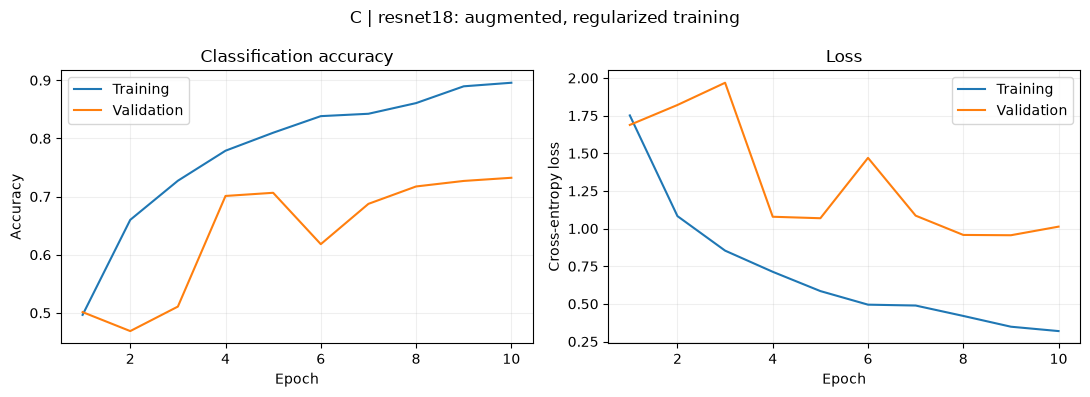

alexnet | epoch 01/10 | training accuracy=0.023 | validation accuracy=0.027 | validation loss=3.613
alexnet | epoch 02/10 | training accuracy=0.023 | validation accuracy=0.026 | validation loss=3.613
alexnet | epoch 03/10 | training accuracy=0.025 | validation accuracy=0.027 | validation loss=3.612
alexnet | epoch 04/10 | training accuracy=0.023 | validation accuracy=0.027 | validation loss=3.611
alexnet | epoch 05/10 | training accuracy=0.017 | validation accuracy=0.027 | validation loss=3.611
alexnet | epoch 06/10 | training accuracy=0.023 | validation accuracy=0.027 | validation loss=3.611
alexnet | epoch 07/10 | training accuracy=0.021 | validation accuracy=0.027 | validation loss=3.611
alexnet | epoch 08/10 | training accuracy=0.024 | validation accuracy=0.027 | validation loss=3.611
alexnet | epoch 09/10 | training accuracy=0.023 | validation accuracy=0.027 | validation loss=3.611
alexnet | epoch 10/10 | training accuracy=0.022 | validation accuracy=0.027 | validation loss=3.926


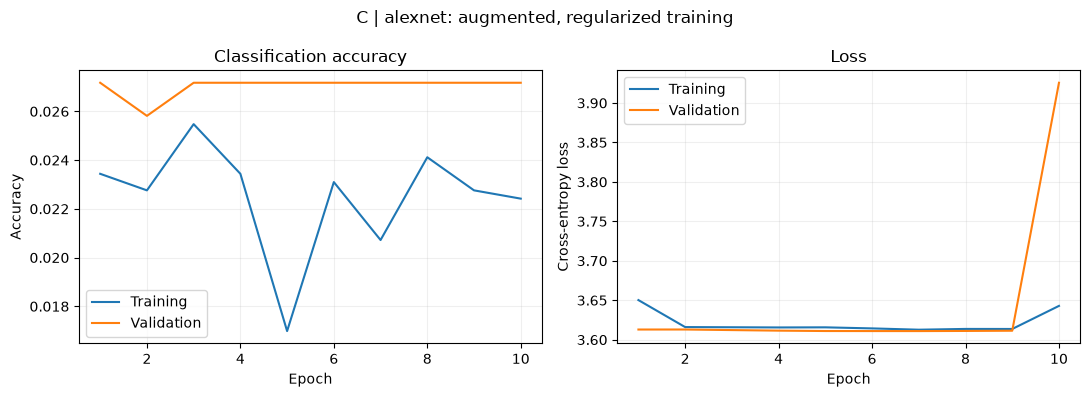

,model,best_epoch,clean_val_loss,clean_val_acc,clean_val_macro_f1,aug_val_acc_mean,aug_val_acc_std,train_seconds
0,resnet18,9,0.955868,0.726902,0.727916,0.718750,0.00986,293.886627
1,alexnet,7,3.610933,0.027174,0.001430,0.027174,0.00000,211.524452


In [16]:
c_rows = []
c_histories = {}

if RUN_C:
    train_c, val_c, val_c_aug, _ = make_loaders(
        augment=True, cutout_p=0.5, cutout_size=32
    )
    for name in MODEL_NAMES:
        model, history, best_epoch = fit_model(
            name, True, train_c, val_c,
            epochs=EPOCHS_C, lr=0.001, weight_decay=1e-4,
            early_stopping=True, patience=PATIENCE,
        )
        clean_scores = run_epoch(model, val_c)
        # Revisit the same validation images with newly sampled flips, rotations and masks.
        augmented_scores = [run_epoch(model, val_c_aug) for _ in range(3)]
        c_rows.append({
            "model": name,
            "best_epoch": best_epoch,
            "clean_val_loss": clean_scores["loss"],
            "clean_val_acc": clean_scores["acc"],
            "clean_val_macro_f1": clean_scores["macro_f1"],
            "aug_val_acc_mean": np.mean([score["acc"] for score in augmented_scores]),
            "aug_val_acc_std": np.std([score["acc"] for score in augmented_scores]),
            "train_seconds": history["epoch_seconds"].sum(),
        })
        c_histories[name] = history
        history.to_csv(OUTPUT_DIR / f"C_{name}_history.csv", index=False)
        plot_history(history, f"C | {name}: augmented, regularized training", f"C_{name}_curves.png")
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    c_results = pd.DataFrame(c_rows)
    c_results.to_csv(OUTPUT_DIR / "C_training_stability_results.csv", index=False)
    display(c_results)
else:
    print("C is disabled. Set RUN_C=True in the configuration to execute this experiment.")

## D. Hyperparameter search using Ray Tune

For each architecture, the notebook evaluates **three random hyperparameter configurations**, using the same ranges as the team's original ResNet18 D implementation:

| Hyperparameter | Search distribution |
|---|---|
| Learning rate | Log-uniform from `1e-4` to `1e-2` |
| Weight decay | Choice of `1e-5` or `1e-4` |
| Batch size | Choice of `16` or `32` |

The objective is to **minimize clean validation cross-entropy loss**. Each trial reports its loss, accuracy and macro-F1 after each epoch. A single concurrent trial reduces GPU-memory contention. No claim of globally optimal hyperparameters is justified by a three-trial search; results identify the best configuration **among the configurations evaluated**.

Trial ranking uses the lowest loss observed during each trial. Accuracy and macro-F1 in the comparison table come from that same epoch.

2026-11-25 14:26:20,679	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


Ray version: 2.60.0


2026-11-25 14:26:30,797	INFO worker.py:2038 -- Started a local Ray instance.
2026-11-25 14:26:36,403	INFO tune.py:253 -- Initializing Ray automatically. For cluster usage or custom Ray initialization, call `ray.init(...)` before `Tuner(...)`.


(raylet) Stack (most recent call first):
(raylet)   File "c:\Users\Robin\anaconda3\envs\MachineLearning\Lib\site-packages\ray\_private\worker.py", line 629 in job_logging_config
(raylet)   File "c:\Users\Robin\anaconda3\envs\MachineLearning\Lib\site-packages\ray\_private\worker.py", line 2201 in _should_ignore_worker_log_prefix
(raylet)   File "c:\Users\Robin\anaconda3\envs\MachineLearning\Lib\site-packages\ray\_private\worker.py", line 2830 in disconnect
(raylet)   File "c:\Users\Robin\anaconda3\envs\MachineLearning\Lib\site-packages\ray\_private\worker.py", line 2132 in shutdown
(raylet)   File "c:\Users\Robin\anaconda3\envs\MachineLearning\Lib\site-packages\ray\_private\worker.py", line 1178 in wrapper


Trial name,accuracy,epoch,loss,val_macro_f1
ray_trainable_cd4f6_00000,0.115489,10,3.19703,0.0851266
ray_trainable_cd4f6_00001,0.048913,5,4.32558,0.0135415
ray_trainable_cd4f6_00002,0.876359,6,0.445743,0.875471


(ray_trainable pid=35812) resnet18 | epoch 01/10 | training accuracy=0.029 | validation accuracy=0.026 | validation loss=3.659
(ray_trainable pid=35812) resnet18 | epoch 02/10 | training accuracy=0.042 | validation accuracy=0.058 | validation loss=3.565
(ray_trainable pid=35812) resnet18 | epoch 03/10 | training accuracy=0.060 | validation accuracy=0.060 | validation loss=3.403
(ray_trainable pid=35812) resnet18 | epoch 04/10 | training accuracy=0.058 | validation accuracy=0.058 | validation loss=3.394
(ray_trainable pid=35812) resnet18 | epoch 05/10 | training accuracy=0.074 | validation accuracy=0.071 | validation loss=3.414
(ray_trainable pid=35812) resnet18 | epoch 06/10 | training accuracy=0.084 | validation accuracy=0.065 | validation loss=3.438
(ray_trainable pid=35812) resnet18 | epoch 07/10 | training accuracy=0.088 | validation accuracy=0.076 | validation loss=3.273
(ray_trainable pid=35812) resnet18 | epoch 08/10 | training accuracy=0.104 | validation accuracy=0.062 | valida

2026-11-25 14:37:04,786	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to 'C:/Users/Robin/Downloads/exam_results/full/ray_runs/pet_resnet18' in 0.0123s.
2026-11-25 14:37:04,790	INFO tune.py:1039 -- Total run time: 628.38 seconds (628.29 seconds for the tuning loop).


(ray_trainable pid=45488) resnet18 | epoch 06/10 | training accuracy=0.984 | validation accuracy=0.876 | validation loss=0.446
(ray_trainable pid=45488) Early stopping at epoch 6; best epoch: 3.


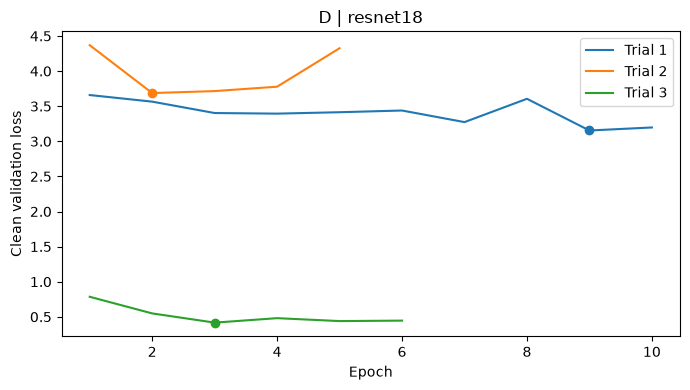

Best observed Ray Tune configuration for resnet18: {'lr': 0.0001542960100551974, 'weight_decay': 0.0001, 'batch_size': 32}


(ray_trainable pid=28864) alexnet | epoch 01/10 | training accuracy=0.022 | validation accuracy=0.027 | validation loss=3.617


Trial name,accuracy,epoch,loss,val_macro_f1
ray_trainable_4d7c0_00000,0.0271739,10,3.61085,0.00143
ray_trainable_4d7c0_00001,0.0271739,9,6.31912,0.00145698
ray_trainable_4d7c0_00002,0.747283,8,0.848317,0.739579


(ray_trainable pid=28864) alexnet | epoch 02/10 | training accuracy=0.026 | validation accuracy=0.027 | validation loss=3.632
(ray_trainable pid=28864) alexnet | epoch 03/10 | training accuracy=0.021 | validation accuracy=0.027 | validation loss=3.612
(ray_trainable pid=28864) alexnet | epoch 04/10 | training accuracy=0.023 | validation accuracy=0.027 | validation loss=3.612
(ray_trainable pid=28864) alexnet | epoch 05/10 | training accuracy=0.022 | validation accuracy=0.027 | validation loss=3.611
(ray_trainable pid=28864) alexnet | epoch 06/10 | training accuracy=0.024 | validation accuracy=0.027 | validation loss=3.611
(ray_trainable pid=28864) alexnet | epoch 07/10 | training accuracy=0.021 | validation accuracy=0.027 | validation loss=3.611
(ray_trainable pid=28864) alexnet | epoch 08/10 | training accuracy=0.021 | validation accuracy=0.027 | validation loss=3.611
(ray_trainable pid=28864) alexnet | epoch 09/10 | training accuracy=0.020 | validation accuracy=0.027 | validation los

2026-11-25 14:46:05,214	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to 'C:/Users/Robin/Downloads/exam_results/full/ray_runs/pet_alexnet' in 0.0136s.
2026-11-25 14:46:05,219	INFO tune.py:1039 -- Total run time: 540.11 seconds (540.07 seconds for the tuning loop).


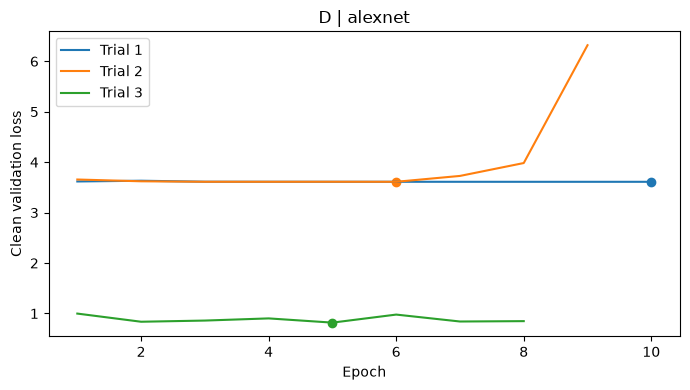

Best observed Ray Tune configuration for alexnet: {'lr': 0.0001542960100551974, 'weight_decay': 0.0001, 'batch_size': 32}


,model,trial,best_epoch,val_loss,val_acc,val_macro_f1,lr,weight_decay,batch_size
0,resnet18,1,9,3.153760,0.114130,0.083170,0.003531,0.00010,16
1,resnet18,2,2,3.687090,0.023098,0.002748,0.005214,0.00001,32
2,resnet18,3,3,0.417177,0.881793,0.880288,0.000154,0.00010,32
3,alexnet,1,10,3.610846,0.027174,0.001430,0.003531,0.00010,16
4,alexnet,2,6,3.611173,0.027174,0.001430,0.005214,0.00001,32
5,alexnet,3,5,0.818860,0.751359,0.752649,0.000154,0.00010,32


In [17]:
d_rows = []
best_configs = {}
ray_results = {}


def best_row(trial):
    """Select the earliest epoch attaining the lowest recorded validation loss."""
    curve = trial.metrics_dataframe
    return curve.loc[curve["loss"].idxmin()]


def ray_trainable(config, model_name):
    """Train and report one sampled configuration to Ray Tune."""
    from ray import tune

    set_seed()
    trial_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    train_dl, val_dl, _, _ = make_loaders(
        batch_size=int(config["batch_size"]), augment=True, cutout_p=0.5
    )
    fit_model(
        model_name, pretrained=True,
        train_loader=train_dl, val_loader=val_dl,
        epochs=EPOCHS_D,
        lr=float(config["lr"]),
        weight_decay=float(config["weight_decay"]),
        early_stopping=True,
        patience=PATIENCE,
        report_fn=tune.report,
        device=trial_device,
    )


if RUN_D:
    from ray import tune

    from ray.tune.search.basic_variant import BasicVariantGenerator

    print("Ray version:", __import__("ray").__version__)
    for name in MODEL_NAMES:
        search_space = {
            "lr": tune.loguniform(1e-4, 1e-2),
            "weight_decay": tune.choice([1e-5, 1e-4]),
            "batch_size": tune.choice([16, 32]),
        }
        trainable = tune.with_resources(
            tune.with_parameters(ray_trainable, model_name=name),
            resources={"cpu": 2, "gpu": 1 if torch.cuda.is_available() else 0},
        )
        tuner = tune.Tuner(
            trainable,
            param_space=search_space,
            tune_config=tune.TuneConfig(
                metric="loss", mode="min", num_samples=3,
                # Reset the search seed per architecture to sample matching settings.
                search_alg=BasicVariantGenerator(random_state=SEED, max_concurrent=1),
            ),
            run_config=tune.RunConfig(
                name=f"pet_{name}",
                storage_path=str((OUTPUT_DIR / "ray_runs").resolve()),
                verbose=2,
            ),
        )
        results = tuner.fit()
        ray_results[name] = results
        successful = [
            result for result in results
            if result.error is None and "loss" in result.metrics
        ]
        if not successful:
            print(f"No successful Ray Tune trials for {name}.")
            continue
        # Compare checkpoints at their best validation epoch, even if training continued.
        winner = min(successful, key=lambda trial: best_row(trial)["loss"])
        best_configs[name] = winner.config
        fig, axis = plt.subplots(figsize=(7, 4))
        for trial_number, trial in enumerate(successful, start=1):
            # The dot marks the checkpoint used to rank this trial.
            curve = trial.metrics_dataframe
            checkpoint = best_row(trial)
            line, = axis.plot(curve["epoch"], curve["loss"], label=f"Trial {trial_number}")
            axis.scatter(checkpoint["epoch"], checkpoint["loss"], color=line.get_color())
            row = best_row(trial)
            d_rows.append({
                "model": name,
                "trial": trial_number,
                "best_epoch": int(row["epoch"]),
                "val_loss": row["loss"],
                "val_acc": row.get("accuracy", float("nan")),
                "val_macro_f1": row.get("val_macro_f1", float("nan")),
                **trial.config,
            })
        axis.set(xlabel="Epoch", ylabel="Clean validation loss", title=f"D | {name}")
        axis.legend()
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f"D_{name}_trial_curves.png", dpi=160)
        plt.show()
        print(f"Best observed Ray Tune configuration for {name}: {winner.config}")

    d_results = pd.DataFrame(d_rows)
    d_results.to_csv(OUTPUT_DIR / "D_ray_tuning_trials.csv", index=False)
    (OUTPUT_DIR / "D_best_configs.json").write_text(
        json.dumps(best_configs, indent=2), encoding="utf-8"
    )
    display(d_results)
else:
    print("D is disabled. Set RUN_D=True in the configuration to run Ray Tune.")

## E. Generalisation to the held-out test set

Each configured architecture is retrained using its selected settings from D. If no tuned configuration is available for a model, the table labels its settings as the part C defaults. Each run restores its lowest clean-validation-loss checkpoint before evaluating the official test images in one pass.

Accuracy counts the fraction of images classified correctly. Macro-F1 averages breed-level F1 scores, giving each breed equal weight. In the confusion matrix, rows are true breeds and columns are predictions. The largest off-diagonal counts identify frequent directional errors.

resnet18 | epoch 01/10 | training accuracy=0.612 | validation accuracy=0.821 | validation loss=0.790
resnet18 | epoch 02/10 | training accuracy=0.886 | validation accuracy=0.853 | validation loss=0.540
resnet18 | epoch 03/10 | training accuracy=0.947 | validation accuracy=0.879 | validation loss=0.423
resnet18 | epoch 04/10 | training accuracy=0.969 | validation accuracy=0.855 | validation loss=0.491
resnet18 | epoch 05/10 | training accuracy=0.982 | validation accuracy=0.863 | validation loss=0.461
resnet18 | epoch 06/10 | training accuracy=0.986 | validation accuracy=0.872 | validation loss=0.455
Early stopping at epoch 6; best epoch: 3.


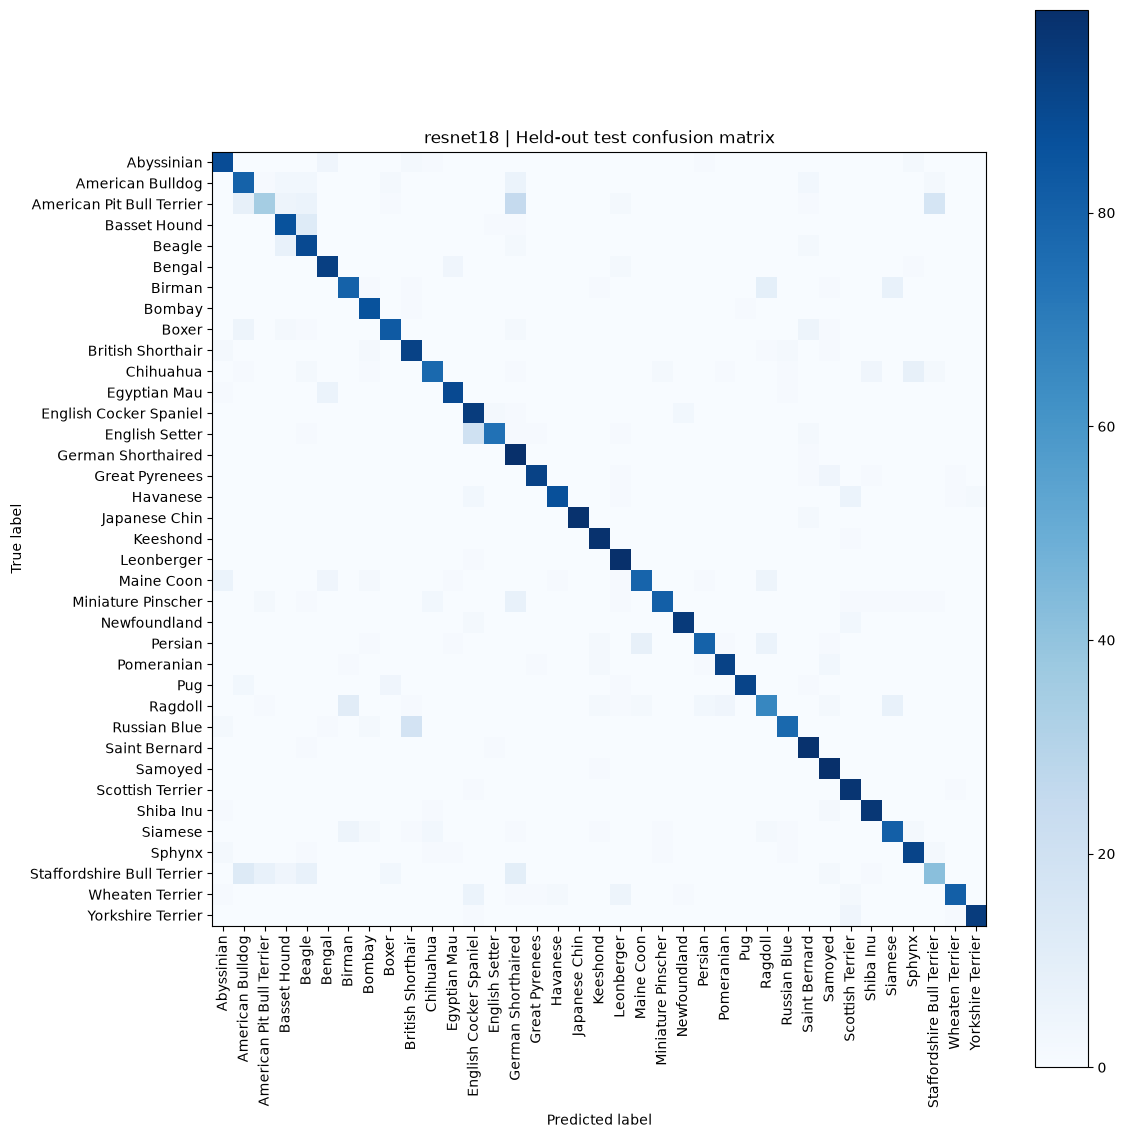

alexnet | epoch 01/10 | training accuracy=0.446 | validation accuracy=0.688 | validation loss=0.998
alexnet | epoch 02/10 | training accuracy=0.696 | validation accuracy=0.735 | validation loss=0.836
alexnet | epoch 03/10 | training accuracy=0.773 | validation accuracy=0.731 | validation loss=0.860
alexnet | epoch 04/10 | training accuracy=0.817 | validation accuracy=0.720 | validation loss=0.903
alexnet | epoch 05/10 | training accuracy=0.844 | validation accuracy=0.751 | validation loss=0.819
alexnet | epoch 06/10 | training accuracy=0.876 | validation accuracy=0.702 | validation loss=0.978
alexnet | epoch 07/10 | training accuracy=0.892 | validation accuracy=0.757 | validation loss=0.841
alexnet | epoch 08/10 | training accuracy=0.902 | validation accuracy=0.747 | validation loss=0.848
Early stopping at epoch 8; best epoch: 5.


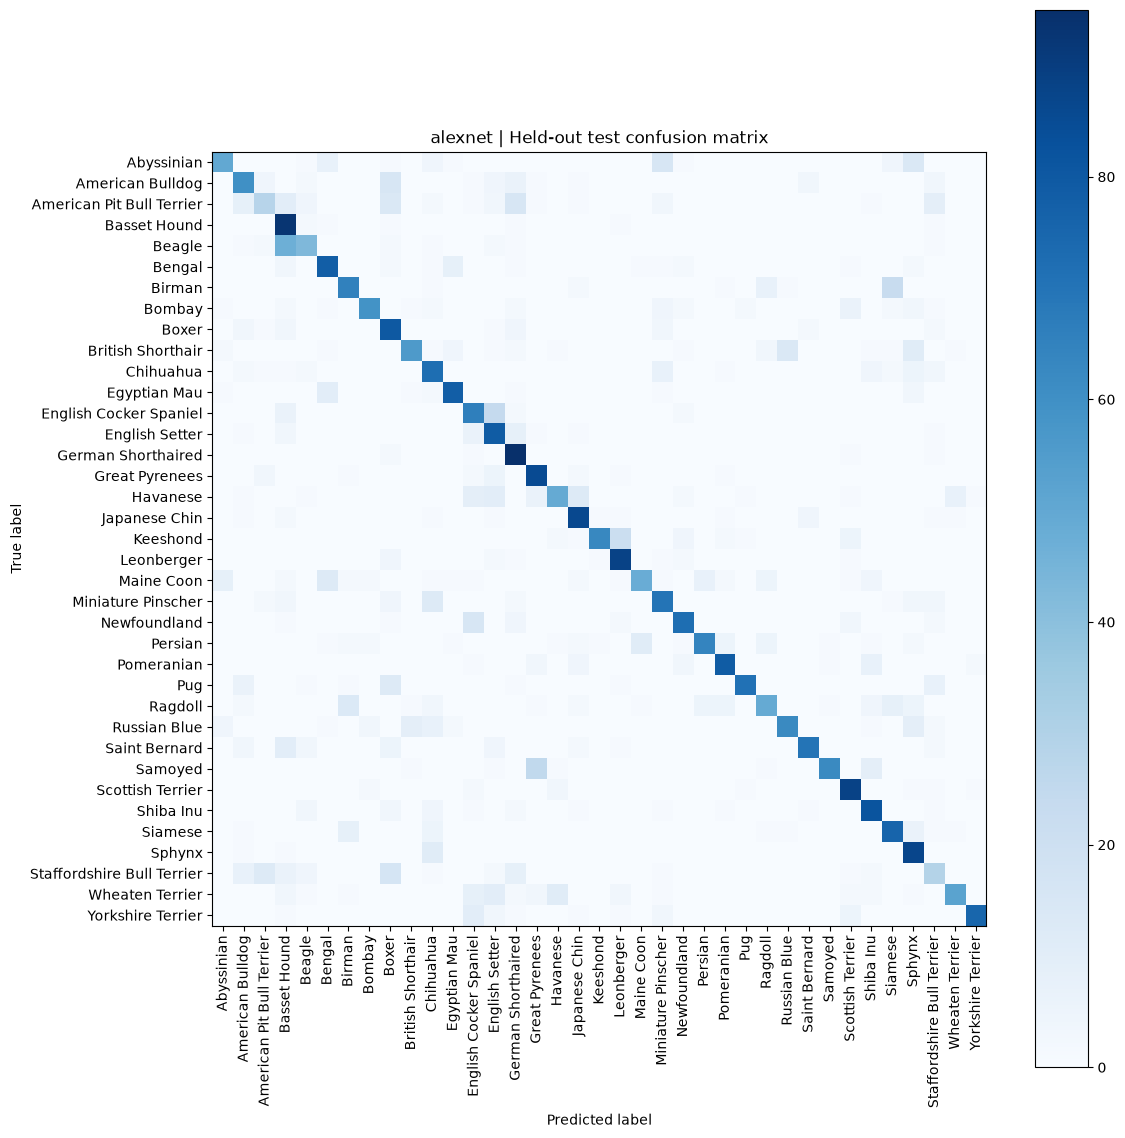

,model,configuration,best_epoch,learning_rate,weight_decay,batch_size,test_loss,test_acc,test_macro_f1
0,resnet18,D tuned,3,0.000154,0.0001,32,0.531395,0.860998,0.857002
1,alexnet,D tuned,5,0.000154,0.0001,32,1.068772,0.683838,0.680452


In [18]:
final_rows = []

# Allow final evaluation in a restarted notebook after a completed Tune run.
saved_configs = OUTPUT_DIR / "D_best_configs.json"
if RUN_FINAL_TEST and not best_configs and saved_configs.exists():
    best_configs = json.loads(saved_configs.read_text(encoding="utf-8"))

if RUN_FINAL_TEST:
    for name in MODEL_NAMES:
        config = best_configs.get(name, {
            "lr": 0.001,
            "weight_decay": 1e-4,
            "batch_size": BATCH_SIZE,
        })
        train_dl, val_dl, _, test_dl = make_loaders(
            batch_size=int(config["batch_size"]), augment=True,
            cutout_p=0.5, cutout_size=32,
        )
        model, history, best_epoch = fit_model(
            name, True, train_dl, val_dl,
            epochs=EPOCHS_C,
            lr=float(config["lr"]),
            weight_decay=float(config["weight_decay"]),
            early_stopping=True,
            patience=PATIENCE,
        )
        # Reuse one set of predictions for the overall scores and breed-level diagnostics.
        test_metrics = run_epoch(model, test_dl, collect_predictions=True)
        true_labels = test_metrics.pop("targets")
        predictions = test_metrics.pop("predictions")
        final_rows.append({
            "model": name,
            "configuration": "D tuned" if name in best_configs else "C defaults",
            "best_epoch": best_epoch,
            "learning_rate": float(config["lr"]),
            "weight_decay": float(config["weight_decay"]),
            "batch_size": int(config["batch_size"]),
            **{f"test_{key}": value for key, value in test_metrics.items()},
        })

        report = classification_report(
            true_labels, predictions, labels=list(range(NUM_CLASSES)),
            target_names=base_test.classes, zero_division=0, output_dict=True,
        )
        pd.DataFrame(report).transpose().to_csv(
            OUTPUT_DIR / f"E_{name}_classification_report.csv"
        )
        matrix = confusion_matrix(
            true_labels, predictions, labels=list(range(NUM_CLASSES))
        )
        figure, axis = plt.subplots(figsize=(12, 12))
        ConfusionMatrixDisplay(matrix, display_labels=base_test.classes).plot(
            ax=axis, cmap="Blues", colorbar=True,
            xticks_rotation="vertical", include_values=False
        )
        axis.set_title(f"{name} | Held-out test confusion matrix")
        figure.tight_layout()
        figure.savefig(
            OUTPUT_DIR / f"E_{name}_confusion_matrix.png", dpi=180,
            bbox_inches="tight"
        )
        plt.show()
        torch.save(model.state_dict(), OUTPUT_DIR / f"E_{name}_weights.pt")
        history.to_csv(OUTPUT_DIR / f"E_{name}_training_history.csv", index=False)
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    final_results = pd.DataFrame(final_rows)
    final_results.to_csv(OUTPUT_DIR / "E_final_test_comparison.csv", index=False)
    display(final_results)
else:
    print("Final evaluation is disabled; enable only after model and hyperparameter selection.")

## Interpretation and limitations

Use the fixed-budget B comparison to assess pretraining. A positive accuracy difference favours ImageNet initialisation. Use the C curves to see whether validation loss starts rising while training loss continues to fall. A gap between clean and augmented accuracy measures sensitivity to the transformations used here.

D compares three sampled configurations per architecture. A winner among three trials can depend on the search range and training budget. All experiments use a single split and training seed. The variation across augmented validation passes cannot establish whether a difference between architectures would persist under retraining.

### Resources

[TorchVision classification models](https://pytorch.org/vision/stable/models.html) · [Oxford-IIIT Pet dataset loader](https://pytorch.org/vision/stable/generated/torchvision.datasets.OxfordIIITPet.html) · [Ray Tune](https://docs.ray.io/en/latest/tune/index.html)